# LSTM Testing
---

## Loading Data
We'll begin by loading the data from our dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load the dataset
df = pd.read_csv("AirQualityUCI.csv", delimiter=";")

print(df.head)


<bound method NDFrame.head of             Date      Time CO(GT)  PT08.S1(CO)  NMHC(GT) C6H6(GT)  \
0     10/03/2004  18.00.00    2,6       1360.0     150.0     11,9   
1     10/03/2004  19.00.00      2       1292.0     112.0      9,4   
2     10/03/2004  20.00.00    2,2       1402.0      88.0      9,0   
3     10/03/2004  21.00.00    2,2       1376.0      80.0      9,2   
4     10/03/2004  22.00.00    1,6       1272.0      51.0      6,5   
...          ...       ...    ...          ...       ...      ...   
9466         NaN       NaN    NaN          NaN       NaN      NaN   
9467         NaN       NaN    NaN          NaN       NaN      NaN   
9468         NaN       NaN    NaN          NaN       NaN      NaN   
9469         NaN       NaN    NaN          NaN       NaN      NaN   
9470         NaN       NaN    NaN          NaN       NaN      NaN   

      PT08.S2(NMHC)  NOx(GT)  PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  \
0            1046.0    166.0        1056.0    113.0        1692.0   
1  

Interesting to note that we have NaN values. We'll want to remove those from our dataset.

In [2]:
df = df.dropna(subset=['CO(GT)'])

print(f"ID\tCO Concentration")
print(df['CO(GT)'].sort_values())

ID	CO Concentration
3501    -200
3301    -200
3302    -200
3303    -200
3304    -200
        ... 
5690     9,2
6696     9,3
6409     9,4
5520     9,5
6672     9,9
Name: CO(GT), Length: 9357, dtype: str


This is better, but notice that we seem to have some values of -200, which does not make sense since we are measuring the concentration of CO. A negative value should not exist. We need to remove that as well. At the same time, we'll convert the column data from strings to floats:

In [3]:
df['CO(GT)'] = df['CO(GT)'].replace(regex=',',value='.').astype(float)
df = df[(df['CO(GT)'] > 0)]

print(f"ID\tCO Concentration")
print(df['CO(GT)'])

ID	CO Concentration
0       2.6
1       2.0
2       2.2
3       2.2
4       1.6
       ... 
9352    3.1
9353    2.4
9354    2.4
9355    2.1
9356    2.2
Name: CO(GT), Length: 7674, dtype: float64


Now we are almost ready to plot the data. Since our data is taken over a timespan, we will want our x-axis to be time. We will have to do some column merging and manipulation to get a format that works for us. Note that the data was collected in 1 hour periods, and date and time is split between two columns.

In [4]:
# Formatting and merging data to properly use date values as x axis
df['Datetime'] = df['Date'] + ' ' + df['Time'].replace(regex=r"\.",value=":")
df['Datetime'] = pd.to_datetime(df['Datetime'],format='%d/%m/%Y %H:%M:%S')

## Plotting
Now we can finally plot our graph

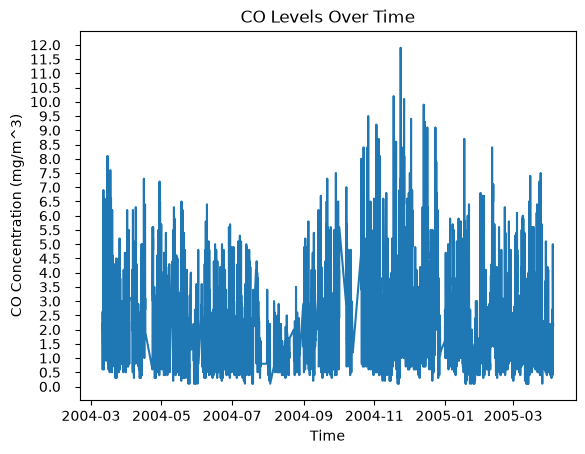

In [5]:
x = df['Datetime'].to_numpy()
y = df['CO(GT)']

fig, ax = plt.subplots()

ax.yaxis.set_major_locator(plt.MultipleLocator(0.5))
plt.plot(x,y)
plt.title("CO Levels Over Time")
plt.ylabel("CO Concentration (mg/m^3)")
plt.xlabel("Time")
plt.tick_params(axis='y',pad=10)

plt.show()

## Preprocessing

We would now like to preprocess the data a bit more so that it can be used to train data:
- Normalize the data
- Create two windows: 24 steps in the past and 1 in the future (prediction). From what I can tell, the best way to implement sliding windows is to simply create a function that returns the data.

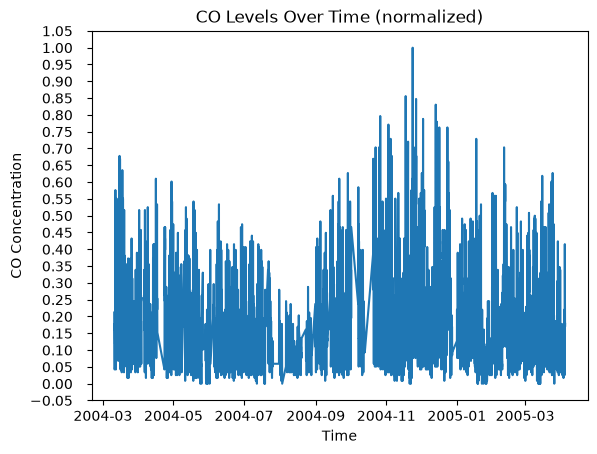

In [6]:
series = df['CO(GT)'].values
norm_series = np.array((series - np.min(series)) / (np.max(series) - np.min(series)))

x = df['Datetime']
y = norm_series

fig, ax = plt.subplots()

ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))

plt.plot(x,y)
plt.title("CO Levels Over Time (normalized)")
plt.ylabel("CO Concentration")
plt.xlabel("Time")
plt.tick_params(axis='y',pad=10)
plt.show()


Note that the graph looks exactly the same, but now the values have been squished to a range between 0 and 1. Following our notes on [sliding windows](README.md#the-sliding-window), we can now construct our sliding windows, and divide them into our 80:20 train-test split.

In [7]:
window_size = 24

X, y = [], []

for i in range(len(norm_series) - window_size):
        X.append(norm_series[i : i + window_size])
        y.append(norm_series[i + window_size])

np.random.shuffle(X)
np.random.shuffle(y)
training_X, testing_X = X[:len(X)*3//4], X[len(X)*3//4:]
training_y, testing_y = X[:len(X)*3//4], X[len(X)*3//4:]

print(f"Training | Size: {len(training_X)}")
print(np.array(training_X))
print(f"Testing | Size: {len(testing_X)}")
print(np.array(testing_X))


Training | Size: 5737
[[0.44915254 0.38983051 0.3559322  ... 0.18644068 0.19491525 0.22033898]
 [0.34745763 0.29661017 0.26271186 ... 0.49152542 0.46610169 0.28813559]
 [0.11864407 0.09322034 0.05932203 ... 0.29661017 0.20338983 0.1440678 ]
 ...
 [0.50847458 0.3220339  0.11864407 ... 0.30508475 0.55084746 0.36440678]
 [0.11016949 0.11016949 0.07627119 ... 0.05084746 0.06779661 0.05932203]
 [0.12711864 0.11016949 0.11016949 ... 0.11016949 0.08474576 0.12711864]]
Testing | Size: 1913
[[0.10169492 0.06779661 0.07627119 ... 0.10169492 0.05932203 0.06779661]
 [0.16949153 0.13559322 0.1779661  ... 0.1779661  0.16949153 0.15254237]
 [0.02542373 0.05084746 0.11016949 ... 0.10169492 0.12711864 0.16101695]
 ...
 [0.06779661 0.11864407 0.45762712 ... 0.03389831 0.02542373 0.03389831]
 [0.3220339  0.25423729 0.16101695 ... 0.15254237 0.22033898 0.24576271]
 [0.16101695 0.11016949 0.09322034 ... 0.29661017 0.16101695 0.11864407]]


## Training the LSTM model
It is finally time to start the training process.

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import ReduceLROnPlateau, ProgbarLogger

pblogger = ProgbarLogger()
rlrop = ReduceLROnPlateau()

EPOCHS = 200
val_split = 0.05

model = Sequential([
    tf.keras.layers.Input(shape=(window_size,1)),
    LSTM(64,return_sequences=True),
    LSTM(64,return_sequences=False),
    Dense(1)
])

model.compile(loss ='mse', optimizer='adam')

"""
model.fit(
    x=None,
    y=None,
    batch_size=None,
    epochs=1,
    verbose=1,
    validation_data=None,
    validation_split=0.0,
    callbacks=None,
    shuffle=True,
)
"""

history = model.fit(
    x=training_X,
    y=training_y,
    batch_size=32,
    epochs=EPOCHS,
    validation_split=val_split,
    callbacks=[pblogger, rlrop]
)

# Plot Training vs Validation Loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss Evolution')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

